# Symmetric double well $V=0.1X^4-0.3X^2$: analysis

Characterises the symmetric double well with coherent-state probes: a single scan of 21
probe centres, reconstructed with $|n|\le2$ harmonics. Produces the symmetric-well curves of
main-text Fig. 3(a), its topology fraction and well-depth difference, its parity test, and the
symmetric-well rows of the SM acquisition, acceptance and Sim tables.

**Input:** `dw.zip` (raw single shots and the vacuum calibration) in the same folder as this notebook.
**Output:** tables, figures and `paper_values.json` in `results_symmetric_double_well/`.

| § | content | used in |
|---|---|---|
| 0 | setup: imports and library functions | — |
| 1 | configuration and raw data | SM *Acquisition* |
| 2 | measurement: momentum scale, probe width, probe-averaged force, raw-shot bootstrap | SM *Measurement*, *Uncertainties* |
| 3 | compiled circuit: $K_g$ from the rotation angles run, and its exact channels | SM *Bosonic QSP construction* |
| 4 | pointwise force reconstruction, Sim, bootstrap topology, Morse-rule cross-check | SM *Pointwise force reconstruction* |
| 5 | band-limited target | SM *Reference curves* |
| 6 | stationary points, well-depth difference, effect of the band limit, parity test | main text; SM *Double-well gates* |
| 7 | acceptance and post-selection | SM *Acceptance and post-selection* |
| 8 | agreement with Sim: band coverage and force errors | SM *Agreement with Sim* |
| 9 | values quoted in the paper | main text, SM |
| 10 | figure panels | main-text Fig. 3(a) |

**Conventions shared by the five analysis notebooks.** Fourier interval $|X|\le2$
(period $L=4$, $\gamma=\pi/2$); probe attenuation $H_n=e^{-\sigma_X^2k_n^2/2}$ with the
measured probe variance $\sigma_X^2$; noise-gain cap $1/H_n\le G=20$; uncertainties from
2000 raw-shot bootstrap replicas; functional-form fits (cubic, Morse) confined to the largest
window $|X|\le W$ over which a simulated perfect device (Sim plus the measured noise) is
consistent with the form (median $p\ge0.10$ at $W$ and at every smaller window); double-well
topology on $|X|\le1.5$.

Run top to bottom. Every number quoted in the paper is collected in `PAPER`, printed
between `===== PAPER VALUES` markers in section 9 and written to `paper_values.json` in the
output folder; `extract_outputs.py` gathers these blocks from all five notebooks.

## 0. Setup
Imports and library functions.

In [1]:
from pathlib import Path
import re, json, hashlib, zipfile, shutil, warnings, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
from scipy.stats import chi2 as chi2_dist
from scipy.linalg import block_diag

# ---------- filesystem / raw-data utilities ----------

def ensure_dir(path):
    p=Path(path); p.mkdir(parents=True,exist_ok=True); return p

def sha256_file(path, block=1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(block),b""): h.update(b)
    return h.hexdigest()

def dedupe_files(paths):
    out=[]; seen=set()
    for p in paths:
        key=sha256_file(p)
        if key not in seen:
            seen.add(key); out.append(Path(p))
    return out

def prepare_source(source, cache_dir):
    source=Path(source)
    cache_dir=ensure_dir(cache_dir)
    if source.is_dir():
        return source
    if source.suffix.lower()==".zip":
        # hash in extraction directory avoids stale cache if ZIP is replaced.
        tag=sha256_file(source)[:12]
        out=cache_dir/f"{source.stem}_{tag}"
        marker=out/".complete"
        if not marker.exists():
            if out.exists(): shutil.rmtree(out)
            out.mkdir(parents=True)
            with zipfile.ZipFile(source,"r") as zf: zf.extractall(out)
            marker.write_text("ok")
        return out
    raise ValueError(f"Unsupported source {source}")

def parse_clock_seconds(name):
    m=re.match(r"(\d{2})-(\d{2})-(\d{2})_",Path(name).name)
    if not m: return np.nan
    h,mn,s=map(int,m.groups()); return h*3600+mn*60+s

def unwrap_clock(times):
    """
    Unwrap only an obvious midnight crossing.
    A long daytime scan (e.g. 09:00--22:00) must NOT be mistaken for overnight.
    """
    x=np.asarray(times,float).copy()
    finite=np.isfinite(x)
    if finite.sum()>1:
        vals=x[finite]
        if vals.max()>=20*3600 and vals.min()<=4*3600:
            x[finite & (x<12*3600)] += 24*3600
    return x


def label_from_name(path):
    m=re.search(r"alpha-([^_]+)_compressed",Path(path).name)
    return m.group(1) if m else Path(path).stem

def alpha_from_name(path):
    label=label_from_name(path).lower()
    if label in {"before","after"} or label.startswith("calib"):
        return None
    sign=-1.0 if label.startswith("m") else 1.0
    core=label[1:] if label.startswith("m") else label
    if core.startswith("p"): core="0."+core[1:]
    try: val=float(core)
    except ValueError: return None
    if re.fullmatch(r"\d+",core): val/=10.0
    return sign*val

def is_reference_path(path):
    s=str(path).lower()
    return any(k in s for k in ("no_gate","no-gate","nogate","reference"))


def binomial_se_jeffreys(k,n):
    k=np.asarray(k,float); n=np.asarray(n,float)
    a=k+0.5; b=n-k+0.5
    return np.sqrt(a*b/((a+b)**2*(a+b+1.0)))

def load_raw_counts(path):
    z=np.load(path)
    required={"single_shot","preselect","y_displace"}
    missing=required.difference(z.files)
    if missing: raise KeyError(f"{path}: missing {sorted(missing)}")
    shot=np.asarray(z["single_shot"],float)
    pre=np.asarray(z["preselect"],float)
    if shot.shape!=pre.shape or shot.ndim!=2:
        raise ValueError(f"{path}: invalid single_shot/preselect shapes")
    accepted=(pre==0)
    nacc1=np.sum((shot==1)&accepted,axis=0).astype(int)
    nacc0=np.sum((shot==0)&accepted,axis=0).astype(int)
    nrej=np.sum(~accepted,axis=0).astype(int)
    nacc=nacc0+nacc1
    ntot=np.full(shot.shape[1],shot.shape[0],dtype=int)
    if "masked_0" in z.files:
        masked=np.asarray(z["masked_0"],float)
        expected=np.where(accepted,shot,np.nan)
        if not np.array_equal(np.isfinite(masked),np.isfinite(expected)):
            raise ValueError(f"{path}: masked_0/preselect mask mismatch")
        finite=np.isfinite(masked)
        if finite.any() and np.max(np.abs(masked[finite]-expected[finite]))>0:
            raise ValueError(f"{path}: masked_0 values differ from preselected single_shot")
    y=nacc1/np.maximum(nacc,1)
    pg=float(nacc.sum()/ntot.sum())
    saved=float(z["num_in_g"]) if "num_in_g" in z.files else np.nan
    if np.isfinite(saved) and abs(pg-saved)>1e-12:
        raise ValueError(f"{path}: reconstructed pg={pg} differs from stored num_in_g={saved}")
    return {
        "x":np.asarray(z["y_displace"],float),"y":y,
        "nacc0":nacc0,"nacc1":nacc1,"nrej":nrej,"nacc":nacc,"ntot":ntot,
        "pg":pg,"saved_pg":saved,"reps":shot.shape[0],"n_cf":shot.shape[1]
    }

# ---------- crosshair / CF derivative ----------

def load_raw_counts_bytes(buf, source_name="<zip-entry>"):
    with np.load(io.BytesIO(buf),allow_pickle=True) as z:
        required={"single_shot","preselect","y_displace"}; missing=required.difference(z.files)
        if missing: raise KeyError(f"{source_name}: missing {sorted(missing)}")
        shot=np.asarray(z["single_shot"],float); pre=np.asarray(z["preselect"],float)
        if shot.shape!=pre.shape or shot.ndim!=2: raise ValueError(f"{source_name}: invalid shapes")
        accepted=(pre==0); n1=np.sum((shot==1)&accepted,axis=0).astype(int); n0=np.sum((shot==0)&accepted,axis=0).astype(int)
        nr=np.sum(~accepted,axis=0).astype(int); na=n0+n1; nt=np.full(shot.shape[1],shot.shape[0],int)
        if "masked_0" in z.files:
            mm=np.asarray(z["masked_0"],float); ex=np.where(accepted,shot,np.nan)
            if not np.array_equal(np.isfinite(mm),np.isfinite(ex)): raise ValueError(f"{source_name}: mask mismatch")
            finite=np.isfinite(mm)
            if finite.any() and np.max(np.abs(mm[finite]-ex[finite]))>0: raise ValueError(f"{source_name}: masked_0 values mismatch")
        y=n1/np.maximum(na,1); pg=float(na.sum()/nt.sum()); saved=float(z["num_in_g"]) if "num_in_g" in z.files else np.nan
        if np.isfinite(saved) and abs(pg-saved)>1e-12: raise ValueError(f"{source_name}: p_g mismatch")
        return {"x":np.asarray(z["y_displace"],float),"y":y,"nacc0":n0,"nacc1":n1,"nrej":nr,"nacc":na,"ntot":nt,
                "pg":pg,"saved_pg":saved,"reps":shot.shape[0],"n_cf":shot.shape[1]}

# ---------------------------------------------------------------------
#  Crosshair calibration: probe width and momentum scale.
#
#  The tomography gate is ECD-3, so a vacuum crosshair is a Gaussian of width
#  w_vac = 1/3 in the swept DAC variable (supplement, "Probe width").
#  The crosshair is a characteristic-function cut of the undisplaced probe, so
#  a width-free fit measures the probe directly:
#
#      sigma_X^2 = (1/2) (w_vac / w)^2 ,
#
#  the quantity the Morse notebook reads off its probe cut.  The
#  same fit gives the readout contrast A, and with the DAC-to-phase-space scale
#  fixed by w_vac the momentum-conversion denominator is
#
#      den = sqrt(2) * A / w_vac .
#
#  A second fit with the width pinned at w_vac (a vacuum probe assumed) is kept
#  as the reference; its relative error is carried by den.  USE_MEASURED_WIDTH
#  in the configuration cell selects the measured width (the convention of
#  every gate) or the pinned reference (sigma_X^2 = 1/2).
# ---------------------------------------------------------------------
CROSSHAIR_W_FIXED = 1.0/3.0        # ECD-3 vacuum crosshair width, by construction
CROSSHAIR_ENFORCE_WIDTH = True     # keep the pinned-width reference fit; same in every gate notebook


def fit_crosshair(path, w_fixed=None, enforce=None):
    """Primary calibration is ydata_0 because force extraction uses masked_0."""
    wf = CROSSHAIR_W_FIXED if w_fixed is None else float(w_fixed)
    en = CROSSHAIR_ENFORCE_WIDTH if enforce is None else bool(enforce)
    z=np.load(path); x=np.asarray(z["xdata"],float)

    def g_fixed(x,b,A,x0): return b+A*np.exp(-0.5*((x-x0)/wf)**2)
    def g_free(x,b,A,x0,w): return b+A*np.exp(-0.5*((x-x0)/w)**2)

    def one(key):
        y=np.asarray(z[key],float); edge=np.r_[y[:4],y[-4:]]
        p0=[edge.mean(), y.max()-edge.mean(), 0.0]

        # width free: the probe width and the readout contrast
        try:
            qopt,qcov=curve_fit(g_free,x,y,p0=p0+[wf],maxfev=30000)
            w_free=float(abs(qopt[3]))
            w_se=float(np.sqrt(max(qcov[3,3],0.0))) if np.all(np.isfinite(qcov)) else np.nan
            s2=0.5*(wf/w_free)**2
            s2_se=(wf**2/w_free**3)*w_se if np.isfinite(w_se) else np.nan
            den_meas=float(qopt[1]*np.sqrt(2)/wf)
        except Exception:
            w_free = w_se = s2 = s2_se = den_meas = np.nan

        if en:
            popt,pcov=curve_fit(g_fixed,x,y,p0=p0,maxfev=30000)
            b,A,x0=popt; w=wf
            grad=np.array([0.0,np.sqrt(2)/w,0.0])
        else:
            popt,pcov=curve_fit(g_free,x,y,p0=p0+[wf],maxfev=30000)
            b,A,x0,w=popt; w=abs(w)
            grad=np.array([0.0,np.sqrt(2)/w,0.0,-A*np.sqrt(2)/(w*w)])
        den=A*np.sqrt(2)/w
        var=float(grad@pcov@grad) if np.all(np.isfinite(pcov)) else 0.0
        se=float(np.sqrt(max(var,0)))

        # ---- momentum scale, applied here so that every force, every
        #      bootstrap draw and every table downstream is consistent -----
        #  contrast A from the width-free fit, DAC-to-phase-space scale from
        #  w_vac: den = sqrt(2) A_free / w_vac.  Its error keeps the relative
        #  error of the pinned-width fit.
        den_used, se_used = den, se
        if USE_MEASURED_WIDTH and np.isfinite(den_meas) and den_meas > 0:
            se_used = se*den_meas/den if den else se      # relative error preserved
            den_used = den_meas

        return {"den":float(den_used),"se":float(se_used),
                "den_pinned_width":float(den),
                "den_measured_width": float(den_meas),
                "measured_width_used": bool(USE_MEASURED_WIDTH),
                "peak":float(b+A),"width":float(abs(w)),
                "width_free":w_free,"width_free_se":w_se,
                "sigma_X2":s2,"sigma_X2_se":s2_se,
                "den_measured_vs_pinned":float(den_meas/den) if den else np.nan}

    p0_=one("ydata_0"); p1=one("ydata_1") if "ydata_1" in z.files else None
    if np.isfinite(p0_["sigma_X2"]):
        SIGMA2_MEASURED.append(float(p0_["sigma_X2"]))   # primary channel only
    return {"path":str(path),"den":p0_["den"],"se":p0_["se"],
            "den_pinned_width":p0_["den_pinned_width"],
            "den_measured_width":p0_["den_measured_width"],
            "measured_width_used":p0_["measured_width_used"],
            "width_mean":p0_["width"],"peak_mean":p0_["peak"],
            "secondary_den":p1["den"] if p1 else np.nan,
            "secondary_se":p1["se"] if p1 else np.nan,
            "channel_disagreement":abs(p0_["den"]-p1["den"]) if p1 else np.nan,
            # diagnostics, not propagated
            "width_free":p0_["width_free"],"width_free_se":p0_["width_free_se"],
            "sigma_X2":p0_["sigma_X2"],"sigma_X2_se":p0_["sigma_X2_se"],
            "den_measured_vs_pinned":p0_["den_measured_vs_pinned"],
            "calibration_mode":(("probe width measured: width-free fit, den = sqrt(2) A / w_vac"
                                  if USE_MEASURED_WIDTH else f"width pinned at {wf:.6f} (vacuum probe assumed)")
                                 if en else "width free, contrast and DAC scale both fitted (NOT the convention)")}

def cf_slope(raw,order=3):
    x=np.asarray(raw["x"],float); y=np.asarray(raw["y"],float); n=np.asarray(raw["nacc"],float)
    if len(x)<order+1: raise ValueError("not enough CF points")
    se=binomial_se_jeffreys(y*n,n)
    scale=float(np.max(np.abs(x)))
    if scale<=0: raise ValueError("CF displacement axis has zero extent")
    u=x/scale
    A=np.column_stack([u**j for j in range(order+1)])
    Aw=A/se[:,None]; yw=y/se
    beta,_,rank,sing=np.linalg.lstsq(Aw,yw,rcond=None)
    cov=np.linalg.pinv(Aw.T@Aw,rcond=1e-12)
    resid=(y-A@beta)/se
    dof=max(len(y)-rank,1)
    return {
        "slope":float(beta[1]/scale),
        "slope_se":float(np.sqrt(max(cov[1,1],0))/scale),
        "chi2":float(resid@resid),"dof":int(dof),
        "p":float(chi2_dist.sf(resid@resid,dof)),
        "condition":float(np.linalg.cond(Aw)),
        "rank":int(rank)
    }

def load_scan(source, cache_dir, name, mu_sign=+1.0, force_sign=+1.0, cf_order=5,
              mu_mode="coherent_alpha", mu_per_label=0.2):
    stream=isinstance(source,dict) and source.get("mode")=="zip_stream"
    if stream:
        cross=[Path(q) for q in source["crosshairs"]]; data_zip=Path(source["data_zip"])
        with zipfile.ZipFile(data_zip) as zf: qsp=[n for n in zf.namelist() if n.lower().endswith(".npz") and "__MACOSX" not in n]
        root=str(data_zip)
    else:
        root=prepare_source(source,cache_dir); files=[q for q in Path(root).rglob("*.npz") if "__MACOSX" not in str(q)]
        cross=dedupe_files([q for q in files if "crosshair" in q.name.lower()])
        qsp=dedupe_files([q for q in files if "qsp_imag_alpha" in q.name.lower() and not is_reference_path(q)])
    if not qsp: raise FileNotFoundError(f"{source}: no QSP files")
    if not cross: raise FileNotFoundError(f"{source}: no crosshair calibration")
    def ckey(q):
        st=Path(q).stem.lower()
        if "before" in st:return (-2,0,st)
        if "after" in st:return (2,0,st)
        mm=re.search(r"crosshair[_-]?vacuum[_-](\d+)",st); return (0,int(mm.group(1)),st) if mm else (0,0,st)
    cross=sorted(cross,key=ckey); cals=[fit_crosshair(q) for q in cross]
    before=[c for c in cals if "before" in Path(c["path"]).name.lower()]; after=[c for c in cals if "after" in Path(c["path"]).name.lower()]
    if before and after:c0,c1=before[0],after[-1];cmode="explicit_before_after_linear_interpolation"
    elif len(cals)>=2:c0,c1=cals[0],cals[-1];cmode="numbered_brackets_linear_interpolation"
    else:c0=c1=cals[0];cmode="single_crosshair_no_drift_information"
    def base(q):return Path(q).name
    def nlabel(q):
        lab=label_from_name(base(q)).lower(); sign=-1.0 if lab.startswith("m") else 1.0; core=lab[1:] if lab.startswith("m") else lab
        if lab in {"before","after"} or lab.startswith("calib"):return None
        if core.startswith("p"):core="0."+core[1:]
        try:return sign*float(core)
        except:return None
    def times(items):
        raw=np.asarray([parse_clock_seconds(base(q)) for q in items],float)
        if mu_mode!="label_step":return unwrap_clock(raw)
        lab=np.asarray([nlabel(q) for q in items],float); rank=np.where(np.isclose(lab,0),0,np.where(lab>0,2*np.abs(lab)-1,2*np.abs(lab)))
        order=np.argsort(rank);out=raw.copy();day=0.;prev=None
        for ii in order:
            tt=raw[ii]+day
            if prev is not None and tt<prev:day+=86400;tt=raw[ii]+day
            out[ii]=tt;prev=tt
        return out
    t=times(qsp);tmin=np.nanmin(t);tmax=np.nanmax(t)
    def cal_at(tt):
        f=0. if tmax==tmin else float(np.clip((tt-tmin)/(tmax-tmin),0,1));den=(1-f)*c0["den"]+f*c1["den"]
        se=c0["se"] if c0["path"]==c1["path"] else np.sqrt(((1-f)*c0["se"])**2+(f*c1["se"])**2);return den,se,f
    zf=zipfile.ZipFile(data_zip) if stream else None
    def raw(q):return load_raw_counts_bytes(zf.read(q),f"{data_zip}:{q}") if stream else load_raw_counts(q)
    rec=[]
    for q,tt in zip(qsp,t):
        rr=raw(q);fit=cf_slope(rr,cf_order);den,dse,f=cal_at(tt);force=force_sign*fit["slope"]/den;stat=fit["slope_se"]/den;cal=abs(force)*dse/den
        lab=label_from_name(base(q));il=nlabel(q);a=alpha_from_name(base(q));mu=float(mu_per_label*il) if mu_mode=="label_step" else float(mu_sign*np.sqrt(2)*a)
        N=int(rr["ntot"].sum());K=int(rr["nacc"].sum())
        rec.append({"file":base(q),"path":f"{data_zip}:{q}" if stream else str(q),"label":lab,"numeric_label":il,"alpha":a,"alpha_physical":mu/np.sqrt(2),
                    "mu":mu,"clock_seconds":tt,"cal_fraction":f,"denominator":den,"denominator_se":dse,"force":float(force),"force_se":float(np.hypot(stat,cal)),
                    "force_se_stat":float(stat),"force_se_cal":float(cal),"pg":rr["pg"],"pg_se":float(binomial_se_jeffreys(K,N)),"reps":rr["reps"],"n_cf":rr["n_cf"],
                    "cf_chi2":fit["chi2"],"cf_dof":fit["dof"],"cf_p":fit["p"],"cf_condition":fit["condition"],"raw":rr})
    if zf:zf.close()
    return {"name":name,"source":source.get("display_name",str(source)) if stream else str(source),"root":root,"records":rec,"reference_records":[],"crosshairs":cals,
            "cal0":c0,"cal1":c1,"calibration_mode":cmode,"mu_sign":mu_sign,"mu_mode":mu_mode,"mu_per_label":mu_per_label,"force_sign":force_sign,"cf_order":cf_order}


def scan_df(scan,include_anchors=False):
    rows=[]
    for r in scan["records"]:
        if r["alpha"] is None and not include_anchors: continue
        rows.append({k:v for k,v in r.items() if k!="raw"})
    return pd.DataFrame(rows)


def audit_scan(scan):
    df=scan_df(scan,True); sci=df[df.alpha.notna()]
    return {
        "scan":scan["name"],"source":scan["source"],"qsp_files":len(df),
        "science_records":len(sci),"unique_alpha":int(sci.alpha.nunique()) if len(sci) else 0,
        "alpha_min":float(sci.alpha.min()) if len(sci) else np.nan,
        "alpha_max":float(sci.alpha.max()) if len(sci) else np.nan,
        "mu_min":float(sci.mu.min()) if len(sci) else np.nan,
        "mu_max":float(sci.mu.max()) if len(sci) else np.nan,
        "reps_min":int(sci.reps.min()) if len(sci) else 0,
        "reps_max":int(sci.reps.max()) if len(sci) else 0,
        "n_crosshairs":len(scan["crosshairs"]),
        "calibration_mode":scan["calibration_mode"],
        "crosshair_start":Path(scan["cal0"]["path"]).name,
        "crosshair_end":Path(scan["cal1"]["path"]).name,
        "cal_start":scan["cal0"]["den"],"cal_end":scan["cal1"]["den"],
        "crosshair_width_start":scan["cal0"].get("width_mean",np.nan),
        "crosshair_width_end":scan["cal1"].get("width_mean",np.nan),
        "cf_order":scan["cf_order"],
        "mu_mode":scan["mu_mode"],"mu_per_label":scan["mu_per_label"],
        "force_sign":scan["force_sign"]
    }

# ---------- Fourier inverse ----------

def attenuation_table(sigma2,nmax=6,L=4.0):
    rows=[]
    for n in range(1,nmax+1):
        k=2*np.pi*n/L; H=np.exp(-0.5*sigma2*k*k)
        rows.append({"n":n,"k_n":k,"H_n":H,"inverse_gain":1/H})
    return pd.DataFrame(rows)

def choose_nmax(sigma2,max_inverse_gain=20,L=4.0,ncap=12):
    nmax=0
    for n in range(1,ncap+1):
        k=2*np.pi*n/L; gain=np.exp(0.5*sigma2*k*k)
        if gain<=max_inverse_gain: nmax=n
        else: break
    if nmax<1: raise ValueError("conditioning threshold rejects n=1")
    return nmax

def fourier_design(x,nmax,sigma2,L=4.0):
    x=np.asarray(x,float); cols=[np.ones_like(x)]
    for n in range(1,nmax+1):
        k=2*np.pi*n/L; H=np.exp(-0.5*sigma2*k*k)
        cols.extend([H*np.cos(k*x),H*np.sin(k*x)])
    return np.column_stack(cols)

def fourier_basis(x,nmax,L=4.0):
    x=np.asarray(x,float); cols=[np.ones_like(x)]
    for n in range(1,nmax+1):
        k=2*np.pi*n/L; cols.extend([np.cos(k*x),np.sin(k*x)])
    return np.column_stack(cols)


# ---------- covariance-preserving multi-scan machinery ----------

def bootstrap_scan_matrix(scan, rng, B):
    """Vectorized empirical count bootstrap with coherent bracket-calibration nuisances."""
    nominal=scan_df(scan).copy().sort_values("mu").reset_index(drop=True)
    records=sorted([r for r in scan["records"] if r["alpha"] is not None],key=lambda r:r["mu"])
    c0,c1=scan["cal0"],scan["cal1"];d0=np.maximum(rng.normal(c0["den"],max(c0["se"],1e-12),B),1e-12)
    d1=d0 if c0["path"]==c1["path"] else np.maximum(rng.normal(c1["den"],max(c1["se"],1e-12),B),1e-12)
    Fb=np.empty((B,len(records)));Ab=np.empty((B,len(records)));degree=scan["cf_order"]
    for col,r in enumerate(records):
        raw=r["raw"]; nt=raw["ntot"].astype(int);ncf=len(nt);n0=np.empty((B,ncf),int);n1=np.empty((B,ncf),int)
        for j,N in enumerate(nt):
            pr=np.array([raw["nacc0"][j],raw["nacc1"][j],raw["nrej"][j]],float);pr/=pr.sum();dr=rng.multinomial(int(N),pr,size=B);n0[:,j]=dr[:,0];n1[:,j]=dr[:,1]
        na=n0+n1;y=n1/np.maximum(na,1);aa=n1+.5;bb=na-n1+.5;se=np.sqrt(aa*bb/((aa+bb)**2*(aa+bb+1)));w=1/np.maximum(se,1e-15)**2
        x=np.asarray(raw["x"]);scale=float(np.max(np.abs(x)));u=x/scale;X=np.column_stack([u**j for j in range(degree+1)])
        M=np.einsum("ji,bj,jk->bik",X,w,X);v=np.einsum("ji,bj,bj->bi",X,w,y);beta=np.linalg.solve(M,v[...,None])[...,0];slope=beta[:,1]/scale
        f=r["cal_fraction"];den=(1-f)*d0+f*d1;Fb[:,col]=scan["force_sign"]*slope/den;Ab[:,col]=na.sum(axis=1)/nt.sum()
    return {"nominal":nominal,"Fb":Fb,"Ab":Ab,"covF":np.cov(Fb,rowvar=False),"covA_abs":np.cov(Ab,rowvar=False)}


def normalized_scan_bundle(bundle):
    """
    Remove only a run-wise acceptance scale by dividing both a-observable and
    q-observable by the same measured p_g(mu=0).  This cannot change q/a.
    It prevents harmless run-to-run acceptance scale changes from masquerading
    as spatial structure when independent scans are combined.
    """
    t=bundle["nominal"].copy()
    i0=int(np.argmin(np.abs(t.mu.to_numpy(float))))
    if abs(float(t.mu.iloc[i0]))>1e-9:
        raise ValueError("each scan must contain the mu=0 normalisation probe")
    p0=float(t.pg.iloc[i0])
    A=t.pg.to_numpy(float)/p0
    Q=t.pg.to_numpy(float)*t.force.to_numpy(float)/p0
    Ab=bundle["Ab"]/bundle["Ab"][:,[i0]]
    Qb=bundle["Ab"]*bundle["Fb"]/bundle["Ab"][:,[i0]]
    return {
        **bundle,"i0":i0,"A":A,"Q":Q,"Ab_norm":Ab,"Qb_norm":Qb,
        "covA":np.cov(Ab,rowvar=False,ddof=1),
        "covQ":np.cov(Qb,rowvar=False,ddof=1),
    }

def gls_fourier(x,y,cov,nmax,sigma2,L=4.0,rtol=1e-10):
    """
    Generalized least squares using only statistically resolved covariance
    eigenmodes.  This handles the exact A(mu=0)=1 normalization constraint
    without inventing a ridge/Tikhonov parameter.
    """
    X=fourier_design(x,nmax,sigma2,L)
    y=np.asarray(y,float); C=np.asarray(cov,float)
    C=(C+C.T)/2
    ev,U=np.linalg.eigh(C)
    vmax=float(np.max(ev)) if ev.size else 0.0
    keep=ev>max(vmax*rtol,1e-18)
    if not np.any(keep):
        raise ValueError("covariance has no resolved positive eigenmodes")
    Z=(U[:,keep]/np.sqrt(ev[keep])).T   # whitening operator
    Xw=Z@X; yw=Z@y
    coef,_,rank,sing=np.linalg.lstsq(Xw,yw,rcond=None)
    H=np.linalg.pinv(Xw,rcond=1e-12)@Z
    pred=X@coef
    rw=Z@(y-pred)
    dof=max(int(keep.sum()-rank),1)
    return {
        "coef":coef,"pred":pred,"H":H,
        "chi2":float(rw@rw),"dof":dof,
        "p":float(chi2_dist.sf(rw@rw,dof)),
        "rank":int(rank),"cov_rank":int(keep.sum()),
        "singular_values":sing,
        "condition":float(np.linalg.cond(Xw)),
    }

def prepare_multiscan_gls(bundles):
    norm=[normalized_scan_bundle(b) for b in bundles]
    mu=np.concatenate([b["nominal"].mu.to_numpy(float) for b in norm])
    A=np.concatenate([b["A"] for b in norm])
    Q=np.concatenate([b["Q"] for b in norm])
    Aboot=np.concatenate([b["Ab_norm"] for b in norm],axis=1)
    Qboot=np.concatenate([b["Qb_norm"] for b in norm],axis=1)
    covA=block_diag(*[b["covA"] for b in norm])
    covQ=block_diag(*[b["covQ"] for b in norm])
    F=np.concatenate([b["nominal"].force.to_numpy(float) for b in norm])
    Fboot=np.concatenate([b["Fb"] for b in norm],axis=1)
    covF=block_diag(*[b["covF"] for b in norm])
    scan_id=np.concatenate([np.full(len(b["nominal"]),i+1,int) for i,b in enumerate(norm)])
    return {
        "bundles":norm,"mu":mu,"A":A,"Q":Q,
        "Aboot":Aboot,"Qboot":Qboot,"covA":covA,"covQ":covQ,
        "F":F,"Fboot":Fboot,"covF":covF,"scan_id":scan_id
    }

def deconvolve_gls(prep,xgrid,nmax,sigma2,L=4.0,a_floor=1e-4):
    fa=gls_fourier(prep["mu"],prep["A"],prep["covA"],nmax,sigma2,L)
    fq=gls_fourier(prep["mu"],prep["Q"],prep["covQ"],nmax,sigma2,L)
    B=fourier_basis(xgrid,nmax,L)
    a=B@fa["coef"]; q=B@fq["coef"]
    force=np.where(a>a_floor,q/a,np.nan)
    caB=prep["Aboot"]@fa["H"].T
    cqB=prep["Qboot"]@fq["H"].T
    aB=caB@B.T
    qB=cqB@B.T
    fB=np.where(aB>a_floor,qB/aB,np.nan)
    return {
        "a":a,"q":q,"force":force,
        "a_boot":aB,"q_boot":qB,"force_boot":fB,
        "fit_a":fa,"fit_q":fq,
        "min_a":float(np.nanmin(a)),"a_floor":a_floor
    }

def roots_slopes(x,y):
    x=np.asarray(x,float); y=np.asarray(y,float); good=np.isfinite(y)
    x=x[good]; y=y[good]; roots=[]
    for i in range(len(x)-1):
        if y[i]==0: roots.append(float(x[i]))
        elif y[i]*y[i+1]<0:
            roots.append(float(x[i]-y[i]*(x[i+1]-x[i])/(y[i+1]-y[i])))
    roots=np.asarray(sorted(set(np.round(roots,12))),float)
    dy=np.gradient(y,x) if len(x)>2 else np.array([])
    slopes=np.array([np.interp(r,x,dy) for r in roots]) if len(dy) else np.array([])
    return roots,slopes

def integrate_force(x,F,zero_at=0.0):
    x=np.asarray(x,float); F=np.asarray(F,float)
    if not np.all(np.isfinite(F)): raise ValueError("force has non-finite values; cannot integrate")
    V=cumulative_trapezoid(F,x,initial=0.0)
    return V-np.interp(zero_at,x,V)

## 1. Configuration and raw data
Input archive, output folder and run settings.

In [2]:
# ---------------- input and output ----------------------------------------
DATA_DIR = Path(".")
OUT   = ensure_dir("results_symmetric_double_well")
CACHE = ensure_dir("_cache_symmetric_double_well")     # extracted archives
# One scan: dw.zip (a browser download may be called "dw (1).zip").
SOURCES = sorted(p for p in DATA_DIR.glob("dw*.zip")
                 if "tilt" not in p.name.lower() and "result" not in p.name.lower())
if not SOURCES:
    raise FileNotFoundError("Place dw.zip beside this notebook.")

# ---------------- acquisition conventions ----------------------------------
MU_MODE = "label_step"       # probe centre mu = MU_PER_LABEL x the numeric file label
MU_PER_LABEL = 0.2
MU_SIGN = +1.0
FORCE_SIGN = +1.0            # force = FORCE_SIGN * slope / den
CF_POLY_ORDER = 5            # degree of the polynomial fitted to each CF cut
EXPECTED_ALPHA_GRID = np.round(np.arange(-1.0, 1.0001, 0.1), 10)   # 21 probe labels

# ---------------- probe width: measured from the vacuum crosshair(s) -------
#  True   the probe variance sigma_X^2 = (1/2)(w_vac/w)^2 is read off the
#         width-free fit of the vacuum crosshair(s), and the momentum scale is
#         sqrt(2) A / w_vac with A from the same fit.  Carried through
#         everything downstream.  This is the convention of every gate.
#  False  reference only: width pinned at w_vac, sigma_X^2 = 1/2.
USE_MEASURED_WIDTH = True
SIGMA2_OVERRIDE    = None    # None: sigma_X^2 from the crosshair(s)
SIGMA2_MEASURED    = []      # filled by the crosshair fitter during the load

# ---------------- estimator ------------------------------------------------
SIGMA2 = 0.5                 # provisional; section 2.1 sets the value used downstream
L = 4.0                      # Fourier period, 2 pi / gamma
MAX_INVERSE_GAIN = 20.0      # noise-gain cap G on 1/H_n
NMAX = choose_nmax(SIGMA2, MAX_INVERSE_GAIN, L)    # provisional; reset in section 2.1
N_BOOT = 2000
RNG_SEED = 20260823
XGRID = np.linspace(-2.0, 2.0, 4001)
TOPOLOGY_WINDOW = (-1.5, 1.5)

print("raw sources:", [str(p) for p in SOURCES])

# ---------------- programmed target ----------------------------------------
A_TARGET, B_TARGET = 0.1, 0.3          # V = -b X^2 + a X^4

def V_target(x):
    x = np.asarray(x, float)
    return -B_TARGET*x**2 + A_TARGET*x**4

def dV_target(x):
    x = np.asarray(x, float)
    return -2*B_TARGET*x + 4*A_TARGET*x**3

print(f"programmed target: V = -{B_TARGET}X^2 + {A_TARGET}X^4")
print(f"topology window {TOPOLOGY_WINDOW}")

GATE = "symmetric double well"
PAPER = {}                   # every number quoted in the paper; printed in section 9

raw sources: ['dw.zip']
programmed target: V = -0.3X^2 + 0.1X^4
topology window (-1.5, 1.5)


### 1.1 Raw extraction
One record per probe centre: degree-5 fit to the characteristic-function cut, momentum scale interpolated between the bracketing vacuum calibrations.

In [3]:
scans = [load_scan(p, CACHE, f"dw_scan_{i+1}", mu_sign=MU_SIGN, force_sign=FORCE_SIGN,
                   cf_order=CF_POLY_ORDER, mu_mode=MU_MODE, mu_per_label=MU_PER_LABEL)
         for i, p in enumerate(SOURCES)]
audit = pd.DataFrame([audit_scan(s) for s in scans])
display(audit)
audit.to_csv(OUT/"01_raw_scan_audit.csv", index=False)

tables = []
for i, s in enumerate(scans):
    t = scan_df(s)
    t = t[t.alpha.notna()].copy()
    t["scan"] = i+1
    tables.append(t)
data = pd.concat(tables, ignore_index=True)
data.to_csv(OUT/"02_extracted_probe_data.csv", index=False)
display(data[["scan", "alpha", "mu", "force", "force_se", "pg", "pg_se", "cf_p", "cf_condition"]])

# ---- completeness of the 21-point sweep(s)
present = np.unique(np.round(data.alpha.to_numpy(float), 10))
missing_alpha = [a for a in EXPECTED_ALPHA_GRID if not np.any(np.isclose(present, a, atol=1e-10))]
print("missing probe labels:", missing_alpha)
if missing_alpha:
    warnings.warn(f"incomplete 21-point probe sweep; missing alpha = {missing_alpha}")
_dup = data.groupby(["scan", "alpha"]).size()
if (_dup > 1).any():
    warnings.warn("duplicate probe records:\n" + str(_dup[_dup > 1]))

,scan,source,qsp_files,science_records,unique_alpha,alpha_min,alpha_max,mu_min,mu_max,reps_min,...,crosshair_start,crosshair_end,cal_start,cal_end,crosshair_width_start,crosshair_width_end,cf_order,mu_mode,mu_per_label,force_sign
0,dw_scan_1,dw.zip,21,21,21,-1.0,1.0,-2.0,2.0,10000,...,crosshair_vacuum.npz,crosshair_vacuum.npz,1.925152,1.925152,0.333333,0.333333,5,label_step,0.2,1.0


,scan,alpha,mu,force,force_se,pg,pg_se,cf_p,cf_condition
0,1,0.0,0.0,-0.081309,0.066566,0.888705,0.000686,0.344337,38.897825
1,1,0.1,0.2,-0.055691,0.066763,0.883371,0.000700,0.058063,38.905629
2,1,-0.1,-0.2,0.051164,0.066607,0.887481,0.000690,0.981297,38.899158
3,1,0.2,0.4,0.035208,0.066703,0.884252,0.000698,0.388255,38.902069
4,1,-0.2,-0.4,0.052661,0.066680,0.885348,0.000695,0.608428,38.906859
5,1,0.3,0.6,-0.034446,0.066649,0.885971,0.000694,0.885971,38.897769
6,1,-0.3,-0.6,0.012047,0.066509,0.889248,0.000685,0.458846,38.901457
7,1,0.4,0.8,-0.074711,0.066580,0.887719,0.000689,0.325283,38.901433
8,1,-0.4,-0.8,0.120047,0.066803,0.882062,0.000704,0.670104,38.897070
9,1,0.5,1.0,0.089036,0.066776,0.881952,0.000704,0.170903,38.882619


missing probe labels: []


## 2. Measurement
### 2.1 Momentum scale and probe width
The vacuum crosshair is a characteristic-function cut of the undisplaced probe, so its fitted width $w$ is the probe width: $\sigma_X^2=\tfrac12(w_{\rm vac}/w)^2$ with $w_{\rm vac}=1/3$ the vacuum width the ECD-3 tomography is built for, as the Morse notebook reads $\sigma_X^2$ off its probe cut. The same fit gives the readout contrast $A$, and $\Lambda=\sqrt2A/w_{\rm vac}$. Where a scan has several crosshairs, $\sigma_X^2$ is their mean. Its uncertainty is not propagated.

In [4]:
# =====================================================================
#  §2.1 --- MOMENTUM-SCALE CALIBRATION.
#  The probe width and the readout contrast both come from the width-free
#  crosshair fit; sigma_X^2 is resolved at the end of this cell.
# =====================================================================
_rows = []
for _si, _s in enumerate(scans, 1):
    for _tag, _c in (("before", _s["cal0"]), ("after", _s["cal1"])):
        _rows.append({"scan": _si, "bracket": _tag, "den": _c["den"], "se": _c["se"],
                      "width_pinned": _c["width_mean"], "width_free": _c["width_free"],
                      "sigma_X2": _c["sigma_X2"],
                      "den_measured_vs_pinned": _c["den_measured_vs_pinned"],
                      "file": Path(_c["path"]).name})
crosshair_audit = pd.DataFrame(_rows)
display(crosshair_audit)
crosshair_audit.to_csv(OUT/"22_crosshair_brackets.csv", index=False)
print(f"calibration mode: {scans[0]['cal0']['calibration_mode']}")
_r = crosshair_audit.den_measured_vs_pinned.to_numpy(float); _r = _r[np.isfinite(_r)]
if len(_r):
    print(f"measured-width / pinned-width denominators = {_r.mean():.4f} on average"
          + (" (in use)" if USE_MEASURED_WIDTH else " (not in use; sigma_X^2 = 1/2)"))


# ---------------------------------------------------------------------
#  RESOLVE THE PROBE WIDTH USED FROM HERE ON.
#  Every cell below reads SIGMA2 (and n_max derived from it), so this is the
#  only place it is set.  The momentum scale was set inside the crosshair
#  fitter, so the raw forces and the bootstrap that resamples them are
#  consistent with what is reported here.
# ---------------------------------------------------------------------
_s2_all = np.asarray([v for v in SIGMA2_MEASURED if np.isfinite(v)], float)
SIGMA2 = (float(SIGMA2_OVERRIDE) if SIGMA2_OVERRIDE is not None
          else (float(_s2_all.mean()) if _s2_all.size else 0.5))
if not USE_MEASURED_WIDTH:
    SIGMA2 = 0.5

print("\n=== probe width and momentum scale used from here on ===")
print(f"  USE_MEASURED_WIDTH = {USE_MEASURED_WIDTH}"
      + ("" if SIGMA2_OVERRIDE is None else f"   (sigma_X^2 overridden to {SIGMA2_OVERRIDE})"))
if _s2_all.size:
    print(f"  crosshair widths: {_s2_all.size}, sigma_X^2 = {_s2_all.mean():.4f}"
          + (f" +/- {_s2_all.std(ddof=1)/np.sqrt(_s2_all.size):.4f}" if _s2_all.size > 1 else ""))
print(f"  sigma_X^2  = {SIGMA2:.4f}")
if USE_MEASURED_WIDTH:
    print("  momentum scale: sqrt(2) A / w_vac with A from the width-free fit; "
          "every force below carries it.")
else:
    print("  momentum scale: pinned-width denominators (w = 1/3), sigma_X^2 = 1/2.")

NMAX = choose_nmax(SIGMA2, MAX_INVERSE_GAIN, L)
print(f"  n_max      = {NMAX}   (inverse gain "
      f"{np.exp(0.5*SIGMA2*(2*np.pi*NMAX/L)**2):.2f})")
display(attenuation_table(SIGMA2, 4, L))

,scan,bracket,den,se,width_pinned,width_free,sigma_X2,den_measured_vs_pinned,file
0,1,before,1.925152,0.024536,0.333333,0.318515,0.547607,1.0102,crosshair_vacuum.npz
1,1,after,1.925152,0.024536,0.333333,0.318515,0.547607,1.0102,crosshair_vacuum.npz


calibration mode: probe width measured: width-free fit, den = sqrt(2) A / w_vac
measured-width / pinned-width denominators = 1.0102 on average (in use)

=== probe width and momentum scale used from here on ===
  USE_MEASURED_WIDTH = True
  crosshair widths: 1, sigma_X^2 = 0.5476
  sigma_X^2  = 0.5476
  momentum scale: sqrt(2) A / w_vac with A from the width-free fit; every force below carries it.
  n_max      = 2   (inverse gain 14.91)


,n,k_n,H_n,inverse_gain
0,1,1.570796,0.508860,1.965177
1,2,3.141593,0.067049,14.914445
2,3,4.712389,0.002288,437.135407
3,4,6.283185,0.000020,49479.854854


### 2.2 Probe-averaged force and raw-shot bootstrap
2000 replicas resampling the raw shots at every point of every cut and drawing every calibration from its fitted error.

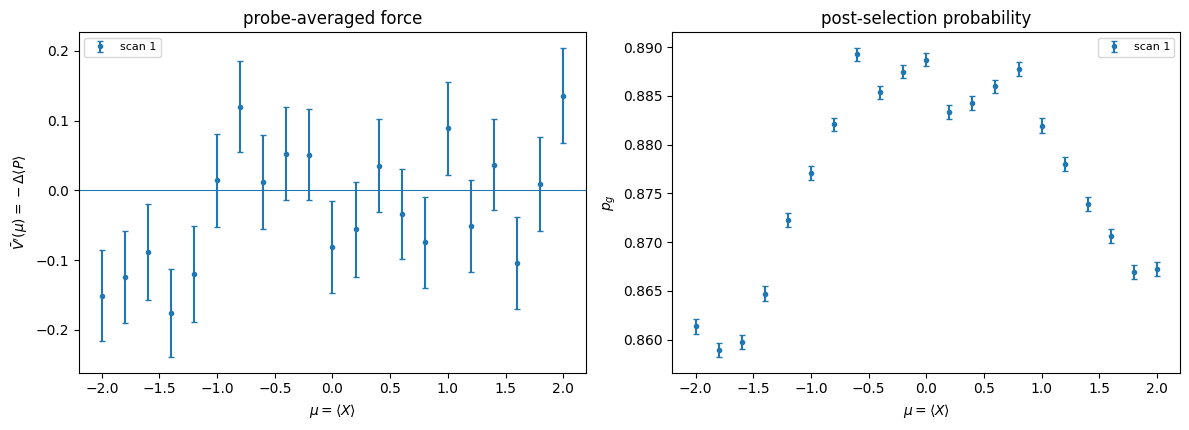

In [5]:
rng = np.random.default_rng(RNG_SEED)
boot_bundles = [bootstrap_scan_matrix(s, rng, N_BOOT) for s in scans]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for i, b in enumerate(boot_bundles):
    t = b["nominal"]
    axes[0].errorbar(t.mu, t.force, yerr=np.sqrt(np.clip(np.diag(b["covF"]), 0, np.inf)),
                     fmt="o", ms=3, capsize=2, label=f"scan {i+1}")
    axes[1].errorbar(t.mu, t.pg, yerr=np.sqrt(np.clip(np.diag(b["covA_abs"]), 0, np.inf)),
                     fmt="o", ms=3, capsize=2, label=f"scan {i+1}")
axes[0].axhline(0, lw=0.8)
axes[0].set_ylabel(r"$\bar V'(\mu)=-\Delta\langle P\rangle$"); axes[0].set_title("probe-averaged force")
axes[1].set_ylabel(r"$p_g$"); axes[1].set_title("post-selection probability")
for ax in axes:
    ax.set_xlabel(r"$\mu=\langle X\rangle$"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/"04_raw_force_scans.png", dpi=300); plt.show()

## 3. Compiled circuit
Built from the rotation angles that were run. $w=|K_g|^2$ and $q=-\mathrm{Im}[K_g^*K_g']$ are exact Fourier series of degree $M$, so the probe average of each is exact.

In [6]:
# =====================================================================
#  §3 --- THE COMPILED CIRCUIT.
#  Supplement, "Post-selected Kraus operator".
#
#  a(X) = |K_g|^2 and q(X) = -Im[K_g* K_g'] are EXACT finite Fourier series of
#  order M on the design period L, because K_g carries harmonics e^{i m gamma X}
#  with |m| <= M/2 of a single parity and both channels are quadratic in K_g.
#  Their coefficients come off by FFT to machine precision, and the
#  coherent-probe average is the closed form e^{-sigma^2 k^2/2} per harmonic.
# =====================================================================

# Symmetric-DW rotation angles actually run: 13 rotations, M = 12.
ROTS = [
    (0.252632, 0.0302548, -2.11279),
    (1.26653,  3.12271,   0.0),
    (1.17213,  3.22627,   0.0),
    (1.08697,  3.11287,   0.0),
    (1.00808,  0.101898,  0.0),
    (0.936294, 1.5275,    0.0),
    (0.168949, 4.81704,   0.0),
    (0.928273, 5.99153,   0.0),
    (1.00288,  3.16116,   0.0),
    (1.09089,  2.97578,   0.0),
    (1.16624,  3.04565,   0.0),
    (1.24,     0.0498915, 0.0),
    (0.252994, 0.530284,  0.0),
]
QSP_ORDER_M = len(ROTS) - 1
BETA = 2*np.pi/L                      # gamma = pi/2 for L = 4
assert abs(L - 4.0) < 1e-12, "design period is not 4; check the configuration"


def R_general(theta, phi, lam):
    return np.array([[np.exp(1j*(lam+phi))*np.cos(theta), np.exp(1j*phi)*np.sin(theta)],
                     [np.exp(1j*lam)*np.sin(theta),      -np.cos(theta)]], complex)


_RL = [R_general(*r) for r in ROTS]


def K_Kp(x):
    """Compiled accepted branch K_g(x) and its exact derivative."""
    S_  = np.array([[0, np.exp(1j*BETA*x/2)],
                    [np.exp(-1j*BETA*x/2), 0]], complex)
    Sp_ = np.array([[0, 1j*BETA/2*np.exp(1j*BETA*x/2)],
                    [-1j*BETA/2*np.exp(-1j*BETA*x/2), 0]], complex)
    U  = _RL[0].copy(); Up = np.zeros((2, 2), complex)
    for j in range(1, len(_RL)):
        Up = _RL[j] @ (Sp_ @ U + S_ @ Up)
        U  = _RL[j] @ S_ @ U
    return U[0, 0], Up[0, 0]


def _channel_coeffs(nfft=512):
    xq = np.arange(nfft)/nfft*L
    v  = [K_Kp(float(t)) for t in xq]
    K  = np.array([z[0] for z in v]); Kp = np.array([z[1] for z in v])
    return np.fft.fft(np.abs(K)**2)/nfft, np.fft.fft(-np.imag(np.conj(K)*Kp))/nfft


CA, CQ = _channel_coeffs()
_tail = max(max(abs(CA[n]) for n in range(QSP_ORDER_M+1, QSP_ORDER_M+20)),
            max(abs(CQ[n]) for n in range(QSP_ORDER_M+1, QSP_ORDER_M+20)))
print(f"compiled channels are exact Fourier series of order M = {QSP_ORDER_M}: "
      f"largest coefficient above M = {_tail:.2e}")


def series(c, x, sigma2=0.0, M=None):
    """sum_{|n|<=M} c_n e^{i k_n x}, Gaussian-smoothed when sigma2 > 0.  Exact."""
    m = QSP_ORDER_M if M is None else int(M)
    x = np.asarray(x, float)
    out = np.full(np.shape(x), c[0].real, float)
    for n in range(1, m+1):
        k = 2*np.pi*n/L
        out = out + 2*np.exp(-0.5*sigma2*k*k)*(c[n].real*np.cos(k*x) - c[n].imag*np.sin(k*x))
    return out


def compiled_coherent(mu, sigma2=None):
    """Coherent-probe response -> (F_g, p_g)."""
    s2 = SIGMA2 if sigma2 is None else float(sigma2)
    pg = series(CA, mu, s2)
    return series(CQ, mu, s2)/pg, pg


_v  = [K_Kp(float(t)) for t in XGRID]
_K  = np.array([w[0] for w in _v]); _Kp = np.array([w[1] for w in _v])
XCOMP       = np.asarray(XGRID, float).copy()
AMPL_COMP   = np.abs(_K)
VPHASE_COMP = -np.unwrap(np.angle(_K))
VPHASE_COMP = VPHASE_COMP - np.interp(0.0, XGRID, VPHASE_COMP)
FPOINT_COMP = series(CQ, XGRID)/series(CA, XGRID)

_direct = -np.imag(np.conj(_K)*_Kp)/np.maximum(AMPL_COMP**2, 1e-12)
print(f"pointwise q/a, series vs direct matrix product: "
      f"max |diff| = {np.max(np.abs(FPOINT_COMP-_direct)):.2e}")

print(f"\ncompiled symmetric DW gate: {len(ROTS)} rotations, M = {QSP_ORDER_M}")

compiled channels are exact Fourier series of order M = 12: largest coefficient above M = 4.85e-17
pointwise q/a, series vs direct matrix product: max |diff| = 2.94e-15

compiled symmetric DW gate: 13 rotations, M = 12


## 4. Pointwise force reconstruction
### 4.1 Deconvolution and Sim
Channels normalised per scan by $p_g(\mu=0)$, combined across scans with a block-diagonal covariance, and deconvolved separately by GLS on the resolved modes of the bootstrap covariance, $|n|\le n_{\max}$. Sim is the compiled circuit put through the same frozen inverse.

In [7]:
# Reconstruction input: every probe centre, |mu| <= L/2.  The compiled gate is
# periodic with period L, so mu = -L/2 and +L/2 are two measurements of the same
# point of the series; both are fitted.
def _open_interval(b, half=L/2):
    keep = np.abs(b["nominal"].mu.to_numpy(float)) <= half + 1e-9
    Fb_, Ab_ = b["Fb"][:, keep], b["Ab"][:, keep]
    return {**b, "nominal": b["nominal"][keep].reset_index(drop=True), "Fb": Fb_, "Ab": Ab_,
            "covF": np.cov(Fb_, rowvar=False), "covA_abs": np.cov(Ab_, rowvar=False)}


prep_all = prepare_multiscan_gls(boot_bundles)                           # every probe
prep = prepare_multiscan_gls([_open_interval(b) for b in boot_bundles])  # reconstruction input
print(f"reconstruction input: {len(prep['mu'])} of {len(prep_all['mu'])} measurements (|mu| <= {L/2:g})")
PAPER["recon.input_probe_centres"] = int(len(np.unique(np.round(prep['mu'], 9))))
rec = deconvolve_gls(prep, XGRID, NMAX, SIGMA2, L)
measured_support = (XGRID >= prep_all["mu"].min()) & (XGRID <= prep_all["mu"].max())
topology_support = (XGRID >= TOPOLOGY_WINDOW[0]) & (XGRID <= TOPOLOGY_WINDOW[1])

roots, slopes = roots_slopes(XGRID[topology_support], rec["force"][topology_support])
topology = bool(len(roots) == 3 and slopes[0] > 0 and slopes[1] < 0 and slopes[2] > 0)
print("w channel GLS: chi2/dof =", rec["fit_a"]["chi2"], "/", rec["fit_a"]["dof"], " p =", rec["fit_a"]["p"])
print("q channel GLS: chi2/dof =", rec["fit_q"]["chi2"], "/", rec["fit_q"]["dof"], " p =", rec["fit_q"]["p"])
print("minimum reconstructed w(X) =", rec["min_a"])
print("stationary points on the topology window:", roots, " minimum-barrier-minimum:", topology)


# ---- Sim: the compiled circuit, probe-averaged at the same centres,
#      normalised per scan as the data and put through the same frozen inverse
PG_COMP_MU = series(CA, prep["mu"], SIGMA2)
Q_COMP_MU  = series(CQ, prep["mu"], SIGMA2)
_An, _Qn, _off = [], [], 0
for _b in prep["bundles"]:
    _n  = len(_b["nominal"])
    _j0 = int(np.argmin(np.abs(_b["nominal"].mu.to_numpy(float))))
    _p  = PG_COMP_MU[_off:_off+_n]
    _q  = Q_COMP_MU[_off:_off+_n]
    _An.append(_p/_p[_j0])
    _Qn.append(_q/_p[_j0])
    _off += _n
A_COMP_N = np.concatenate(_An)
Q_COMP_N = np.concatenate(_Qn)

_B  = fourier_basis(XGRID, NMAX, L)
_ac = _B @ (rec["fit_a"]["H"] @ A_COMP_N)
_qc = _B @ (rec["fit_q"]["H"] @ Q_COMP_N)
F_COMP_EST = np.where(_ac > rec["a_floor"], _qc/_ac, np.nan)


def integrate_masked(F_all, mask=None, zero_at=0.0, x_all=None):
    """Integrate a force curve that may carry NaN (where the reconstructed
    acceptance falls below a_floor) over its finite points only."""
    x = XGRID if x_all is None else np.asarray(x_all, float)
    F = np.asarray(F_all, float)
    ok = np.isfinite(F) if mask is None else (np.asarray(mask, bool) & np.isfinite(F))
    out = np.full(x.shape, np.nan, float)
    if int(ok.sum()) >= 2:
        out[ok] = integrate_force(x[ok], F[ok], zero_at=zero_at)
    return out

reconstruction input: 21 of 21 measurements (|mu| <= 2)
w channel GLS: chi2/dof = 162.81595264296777 / 15  p = 6.726940297816362e-27
q channel GLS: chi2/dof = 25.14912615396346 / 16  p = 0.0672392763951928
minimum reconstructed w(X) = 0.8886692385004828
stationary points on the topology window: [-1.0458458  -0.04376725  0.93562189]  minimum-barrier-minimum: True


### 4.2 Bootstrap through the frozen inverse
Every replica passes through the same inverse; the topology fraction is the fraction of replicas with the minimum–barrier–minimum ordering on the topology window.

In [8]:
boot_force = np.asarray(rec["force_boot"])
boot_a = np.asarray(rec["a_boot"])
flo, fhi = np.nanpercentile(boot_force, [2.5, 97.5], axis=0)

topo = []; nonphysical = 0
for a_b, f_b in zip(boot_a, boot_force):
    physical = bool(np.all(a_b[topology_support] > rec["a_floor"]) and
                    np.all(np.isfinite(f_b[topology_support])))
    nonphysical += not physical
    r, s = roots_slopes(XGRID[topology_support], f_b[topology_support])
    topo.append(bool(physical and len(r) == 3 and s[0] > 0 and s[1] < 0 and s[2] > 0))
topology_fraction = float(np.mean(topo))
print("bootstrap replicas =", len(boot_force))
print("replicas with nonphysical acceptance =", nonphysical)
print(f"minimum-barrier-minimum in {100*topology_fraction:.1f}% of replicas")

bootstrap replicas = 2000
replicas with nonphysical acceptance = 0
minimum-barrier-minimum in 98.2% of replicas


### 4.3 The Morse-gate rule applied to this probe
The Morse reconstruction (`05_morse`, section 4) spends the noise budget of hard truncation at
the gain cap on a smooth rolloff through $|n|\le8$: harmonic $n$ is returned with gain
$g_n=H_n/(H_n^2+\epsilon n^2)$, with $\epsilon$ fixed by $\sum_{n=1}^{8}g_n^2=\sum_{n\le n_{\max}}H_n^{-2}$.
The fraction of harmonic $n$ it keeps is $H_ng_n$. Applied to this coherent probe, the rule is
compared here with the hard cut at $|n|\le n_{\max}$ used for this gate (SM *Pointwise force
reconstruction*). Nothing downstream uses it.

In [9]:
# =====================================================================
#  CROSS-CHECK: the regularised rule of the Morse gate on this probe.
#  eps is fixed by the gain cap alone, as in 05_morse.ipynb:
#      sum_{n=1..8} g_n^2 = sum_{n<=n_max} 1/H_n^2,   g_n = H_n/(H_n^2 + eps n^2)
#  and harmonic n keeps the fraction H_n g_n = H_n^2/(H_n^2 + eps n^2).
#  Only printed and quoted; this gate is reconstructed by hard truncation.
# =====================================================================
from scipy.optimize import brentq as _mr_brentq

MORSE_RULE_NMAX, MORSE_RULE_P = 8, 2           # as in 05_morse.ipynb


def _mr_H(n):
    return float(np.exp(-0.5*SIGMA2*(2*np.pi*n/L)**2))


_mr_target = sum(_mr_H(n)**-2 for n in range(1, NMAX + 1))
_mr_power = lambda eps: sum((_mr_H(n)/(_mr_H(n)**2 + eps*n**MORSE_RULE_P))**2
                            for n in range(1, MORSE_RULE_NMAX + 1))
MORSE_RULE_EPS = 10**_mr_brentq(lambda le: _mr_power(10**le) - _mr_target, -14, 2)
MORSE_RULE_KEPT = {n: _mr_H(n)**2/(_mr_H(n)**2 + MORSE_RULE_EPS*n**MORSE_RULE_P)
                   for n in range(1, MORSE_RULE_NMAX + 1)}

print(f"probe sigma_X^2 = {SIGMA2:.4f};  hard cut at the gain cap: |n| <= {NMAX}")
print(f"Morse-gate rule: eps = {MORSE_RULE_EPS:.3e}")
print(f"{'n':>4}{'1/H_n':>11}{'fraction kept':>15}")
for _n, _f in MORSE_RULE_KEPT.items():
    print(f"{_n:4d}{1/_mr_H(_n):11.3g}{_f:15.4f}")

probe sigma_X^2 = 0.5476;  hard cut at the gain cap: |n| <= 2
Morse-gate rule: eps = 5.559e-05
   n      1/H_n  fraction kept
   1       1.97         0.9998
   2       14.9         0.9529
   3        437         0.0104
   4   4.95e+04         0.0000
   5   2.16e+07         0.0000
   6   3.65e+10         0.0000
   7   2.38e+14         0.0000
   8   5.99e+18         0.0000


## 5. Band-limited target
The programmed force truncated to the retained harmonics $|n|\le n_{\max}$; it uses no data and isolates the distortion of the band limit itself.

In [10]:
# =====================================================================
#  BAND-LIMITED TARGET: the programmed force truncated to |n| <= n_max on
#  the Fourier interval [-L/2, L/2).  No data.
# =====================================================================
def band_limit(fn, nmax=None, L=L, nfft=8192):
    # truncate fn to |n| <= nmax harmonics on the design interval
    nm = NMAX if nmax is None else int(nmax)
    xq = -L/2 + np.arange(nfft)/nfft*L
    yq = np.asarray(fn(xq), float)
    c  = {n: np.mean(yq*np.exp(-1j*2*np.pi*n/L*xq)) for n in range(nm+1)}
    def g(xx):
        xx = np.asarray(xx, float)
        out = np.full(xx.shape, c[0].real)
        for n in range(1, nm+1):
            k = 2*np.pi*n/L
            out = out + 2*(c[n].real*np.cos(k*xx) - c[n].imag*np.sin(k*xx))
        return out
    return g


def stationary_points(y, x):
    # sign-change roots, near-duplicates merged
    y = np.asarray(y, float); r = []
    for i in np.where(np.diff(np.sign(y)) != 0)[0]:
        d = y[i+1] - y[i]
        xr = x[i] - y[i]*(x[i+1]-x[i])/d if d else x[i]
        if not r or abs(xr - r[-1]) > 1e-6:
            r.append(xr)
    return np.asarray(r)


_x = np.linspace(TOPOLOGY_WINDOW[0], TOPOLOGY_WINDOW[1], 200001)
print(f"stationary points on |X| <= {TOPOLOGY_WINDOW[1]}:")
print(f"  programmed    {np.round(stationary_points(dV_target(_x), _x), 4).tolist()}")
print(f"  band-limited  {np.round(stationary_points(band_limit(dV_target)(_x), _x), 4).tolist()}")

stationary points on |X| <= 1.5:
  programmed    [-1.2247, 0.0, 1.2247]
  band-limited  [-0.9772, -0.0002, 0.9768]


## 6. Symmetric double well
### 6.1 Stationary points along the ladder
Programmed force, compiled force, Sim and experiment on the topology window $|X|\le1.5$.

In [11]:
# =====================================================================
#  §6.1 --- LADDERS.
#      programmed target -> compiled exact -> compiled through the estimator
#      -> experiment
#
#  Each adjacent pair isolates one effect:
#    target      -> compiled exact          Fourier truncation at order M
#    compiled    -> compiled via estimator  the band limit of the inverse
#    via estimator -> experiment            the device
#
#  Only the last comparison is a hardware statement.  The middle rung is the
#  one the experiment must be read against, because it alone has been through
#  the same band limit as the data.
#
#  The helpers defined here are reused by §6.2 and §6.3.
# =====================================================================

def roots_dedup(x, y, tol=1e-6):
    """Sign-change roots with slopes, near-coincident roots merged."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    r, s = [], []
    for i in np.where(np.diff(np.sign(y)) != 0)[0]:
        d = y[i+1] - y[i]
        xr = x[i] - y[i]*(x[i+1]-x[i])/d if d else x[i]
        if r and abs(xr - r[-1]) <= tol:
            continue
        r.append(xr); s.append(d/(x[i+1]-x[i]))
    return np.asarray(r), np.asarray(s)


def well_metrics(f_curve, mask=None):
    """Stationary points, barrier height and well-depth difference for one
    force curve, on the topology window.  The potential is obtained by
    integrating the force, so its overall constant cancels throughout.
    Returns None if the curve is not minimum-barrier-minimum."""
    tw = topology_support if mask is None else mask
    xw = XGRID[tw]
    r, s = roots_dedup(xw, np.asarray(f_curve, float)[tw])
    if not (len(r) == 3 and s[0] > 0 and s[1] < 0 and s[2] > 0):
        return None
    V  = integrate_force(xw, np.asarray(f_curve, float)[tw], zero_at=float(r[1]))
    VL = float(np.interp(r[0], xw, V))
    VR = float(np.interp(r[2], xw, V))
    return {"left_minimum": r[0], "barrier": r[1], "right_minimum": r[2],
            "V_left": VL, "V_right": VR,
            "barrier_height_from_deeper": 0.0 - min(VL, VR),
            "well_depth_difference": VR - VL,
            "well_separation": r[2] - r[0]}


# The four rungs, in order.
LADDER_CURVES = (
    ("programmed target",          np.asarray(dV_target(XGRID), float)),
    ("compiled exact",             np.asarray(FPOINT_COMP, float)),
    ("compiled through estimator", np.asarray(F_COMP_EST, float)),
    ("experiment",                 np.asarray(rec["force"], float)),
)

# ---- stationary-point ladder ------------------------------------------
_ladder = []
for _name, _curve in LADDER_CURVES:
    _rt, _sl = roots_dedup(XGRID[topology_support], _curve[topology_support])
    _ok = bool(len(_rt) == 3 and _sl[0] > 0 and _sl[1] < 0 and _sl[2] > 0)
    _ladder.append({"curve": _name, "n_stationary_points": len(_rt),
                    "min_barrier_min": _ok,
                    "left_minimum":  _rt[0] if len(_rt) == 3 else np.nan,
                    "barrier":       _rt[1] if len(_rt) == 3 else np.nan,
                    "right_minimum": _rt[2] if len(_rt) == 3 else np.nan,
                    "separation": (_rt[2]-_rt[0]) if len(_rt) == 3 else np.nan})
root_ladder = pd.DataFrame(_ladder)
display(root_ladder)
root_ladder.to_csv(OUT / "22b_stationary_point_ladder.csv", index=False)

,curve,n_stationary_points,min_barrier_min,left_minimum,barrier,right_minimum,separation
0,programmed target,3,True,-1.224745,0.000000,1.224745,2.449489
1,compiled exact,7,False,NaN,NaN,NaN,NaN
2,compiled through estimator,3,True,-1.004361,-0.001777,0.969012,1.973373
3,experiment,3,True,-1.045846,-0.043767,0.935622,1.981468


### 6.2 Topology and well-depth difference
The stationary points, barrier height and well-depth difference $\delta_{LR}=V(X_R)-V(X_L)$ along the ladder, with bootstrap intervals for the experiment. The paper compares the topology and $\delta_{LR}$ against Sim; the band limit sets the positions and the barrier height (SM *Double-well gates: stationary points*).

In [12]:
# =====================================================================
#  §6.2 --- TOPOLOGY AND WELL-DEPTH DIFFERENCE along the ladder.
#
#  Every quantity is evaluated for the four rungs (programmed target ->
#  compiled exact -> Sim -> experiment); the bootstrap spread is attached to
#  the experiment only.  The comparison that carries hardware information is
#  the experiment against Sim, which has been through the same band limit.
# =====================================================================
_rungs = {_name: well_metrics(_curve) for _name, _curve in LADDER_CURVES}
for _n, _m in _rungs.items():
    if _m is None:
        print(f"NOTE: '{_n}' is not minimum-barrier-minimum on the topology window.")
_nom = _rungs["experiment"]
if _nom is None:
    raise RuntimeError("the reconstruction is not minimum-barrier-minimum on the topology window")
_est = _rungs["compiled through estimator"]

# ---- bootstrap, experiment only --------------------------------------
_rows = []
for _a_b, _f_b in zip(boot_a, boot_force):
    if not np.all(_a_b[topology_support] > rec["a_floor"]) \
       or not np.all(np.isfinite(_f_b[topology_support])):
        continue
    _m = well_metrics(_f_b)
    if _m is not None:
        _rows.append(_m)
_bt = pd.DataFrame(_rows)
_ci = _bt.quantile([0.025, 0.5, 0.975])
_sd = _bt.std(ddof=1)
_cols = list(_ci.columns)

claims_dw = pd.DataFrame({
    "quantity": _cols,
    "programmed": [(_rungs["programmed target"] or {}).get(c, np.nan) for c in _cols],
    "compiled_exact": [(_rungs["compiled exact"] or {}).get(c, np.nan) for c in _cols],
    "compiled_reconstructed": [(_est or {}).get(c, np.nan) for c in _cols],
    "experiment": [_nom[c] for c in _cols],
    "exp_sd": [_sd[c] for c in _cols],
    "exp_lo95": _ci.loc[0.025].values,
    "exp_median": _ci.loc[0.5].values,
    "exp_hi95": _ci.loc[0.975].values,
})
display(claims_dw.round(4))
claims_dw.to_csv(OUT / "30_doublewell_claims.csv", index=False)

_r = claims_dw.set_index("quantity").loc["well_depth_difference"]
print(f"\nminimum-barrier-minimum in {100*topology_fraction:.1f}% of replicas (section 4.2);"
      f" Sim {'has' if _est is not None else 'does not have'} it")
print(f"well-depth difference V(right) - V(left): experiment {_r.experiment:+.4f} +/- {_r.exp_sd:.4f}"
      f"  95% [{_r.exp_lo95:+.4f}, {_r.exp_hi95:+.4f}]  ({abs(_r.experiment)/_r.exp_sd:.1f} sd from zero);"
      f"  Sim {_r.compiled_reconstructed:+.4f};  programmed {_r.programmed:+.4f}")

NOTE: 'compiled exact' is not minimum-barrier-minimum on the topology window.


,quantity,programmed,compiled_exact,compiled_reconstructed,experiment,exp_sd,exp_lo95,exp_median,exp_hi95
0,left_minimum,-1.2247,NaN,-1.0044,-1.0458,0.1283,-1.2944,-1.0479,-0.7825
1,barrier,0.0000,NaN,-0.0018,-0.0438,0.1391,-0.3144,-0.0442,0.2517
2,right_minimum,1.2247,NaN,0.9690,0.9356,0.1423,0.6570,0.9349,1.2357
3,V_left,-0.2250,NaN,-0.2952,-0.4661,0.1751,-0.8546,-0.5060,-0.1753
4,V_right,-0.2250,NaN,-0.2699,-0.4602,0.1881,-0.8709,-0.4986,-0.1594
5,barrier_height_from_deeper,0.2250,NaN,0.2952,0.4661,0.1802,0.1962,0.5273,0.8814
6,well_depth_difference,0.0000,NaN,0.0254,0.0059,0.0647,-0.1226,0.0078,0.1326
7,well_separation,2.4495,NaN,1.9734,1.9815,0.0460,1.8879,1.9863,2.0667



minimum-barrier-minimum in 98.2% of replicas (section 4.2); Sim has it
well-depth difference V(right) - V(left): experiment +0.0059 +/- 0.0647  95% [-0.1226, +0.1326]  (0.1 sd from zero);  Sim +0.0254;  programmed +0.0000


### 6.3 Effect of the band limit
Fourier coefficients of the programmed force on the interval, and the stationary points and depth difference of the band-limited programmed force (the band-limited column of SM *Double-well gates*).

In [13]:
# =====================================================================
#  EFFECT OF THE BAND LIMIT on the stationary points.
#  Fourier coefficients of the programmed force on [-L/2, L/2): the odd force
#  is carried by sin(k_1 X) and sin(k_2 X) only.  The band-limited programmed
#  force (section 5.1) gives the band-limited column of the topology table.
# =====================================================================
_xp = -L/2 + np.arange(8192)/8192*L
_fp = np.asarray(dV_target(_xp), float)
BL_COEFFS = {"a0": float(_fp.mean())}
for _n in (1, 2):
    _k = 2*np.pi*_n/L
    BL_COEFFS[f"a{_n}"] = float(2*np.mean(_fp*np.cos(_k*_xp)))
    BL_COEFFS[f"b{_n}"] = float(2*np.mean(_fp*np.sin(_k*_xp)))
print("programmed force, Fourier coefficients on [-2, 2):",
      ", ".join(f"{k} = {v:+.4f}" for k, v in BL_COEFFS.items()))
BL_METRICS = well_metrics(np.asarray(band_limit(dV_target)(XGRID), float))
if BL_METRICS is None:
    print("band-limited programmed force is not minimum-barrier-minimum on the topology window")
else:
    print("band-limited programmed force: " + ", ".join(
        f"{k} = {v:+.4f}" for k, v in BL_METRICS.items()))

programmed force, Fourier coefficients on [-2, 2): a0 = -0.0002, a1 = +0.0005, b1 = +0.0348, a2 = -0.0005, b2 = -0.4818
band-limited programmed force: left_minimum = -0.9772, barrier = -0.0002, right_minimum = +0.9768, V_left = -0.2850, V_right = -0.2849, barrier_height_from_deeper = +0.2850, well_depth_difference = +0.0001, well_separation = +1.9540


### 6.4 Parity test on the raw force
$s_i=\bar V'(\mu_i)+\bar V'(-\mu_i)$ over the mirror pairs, $\chi^2=s^\top\Sigma_s^{-1}s$ with the bootstrap covariance of the sums; repeated probe centres are averaged first. No reconstruction, no target (SM *Double-well gates: programmable asymmetry*).

In [14]:
# =====================================================================
#  PARITY TEST ON THE RAW FORCE.  Null: the implemented potential is even,
#  so the measured force is odd in the probe centre, F(+mu) = -F(-mu).
#  s_i = F(+mu_i) + F(-mu_i) over the mirror pairs, chi2 = s^T Sigma_s^-1 s
#  with Sigma_s the raw-shot bootstrap covariance of the sums.  Repeated
#  probe centres (several scans) are averaged first.  No inverse, no target.
# =====================================================================
# every probe, including mu = +/-L/2: no periodic model enters this test
_mu_all = np.asarray(prep_all["mu"], float)
_F_all = np.asarray(prep_all["F"], float)
_Fb_all = np.asarray(prep_all["Fboot"], float)

_mu_u = np.unique(np.round(_mu_all, 9))
_T = np.zeros((len(_mu_u), len(_mu_all)))
for _r, _m in enumerate(_mu_u):
    _ix = np.where(np.isclose(_mu_all, _m))[0]
    _T[_r, _ix] = 1.0/len(_ix)
_F_u, _Fb_u = _T @ _F_all, _Fb_all @ _T.T

_pos = np.array([i for i in np.where(_mu_u > 1e-9)[0]
                 if np.any(np.isclose(_mu_u, -_mu_u[i]))], int)
_neg = np.array([int(np.where(np.isclose(_mu_u, -_mu_u[i]))[0][0]) for i in _pos])
_s = _F_u[_pos] + _F_u[_neg]
_Cs = np.cov(_Fb_u[:, _pos] + _Fb_u[:, _neg], rowvar=False, ddof=1)
_Cs = (_Cs + _Cs.T)/2
_ev, _U = np.linalg.eigh(_Cs)
_keep = _ev > max(float(_ev.max())*1e-10, 1e-18)
_chi = float(_s @ ((_U[:, _keep]/_ev[_keep]) @ _U[:, _keep].T) @ _s)
_dof = int(_keep.sum())
PARITY_TEST = {"chi2": _chi, "dof": _dof, "p": float(chi2_dist.sf(_chi, _dof))}

anti = pd.DataFrame({"mu": _mu_u[_pos], "F_plus": _F_u[_pos], "F_minus": _F_u[_neg],
                     "sum": _s, "se_sum": np.sqrt(np.clip(np.diag(_Cs), 0, np.inf))})
anti["z"] = anti["sum"]/anti["se_sum"]
display(anti.round(4))
anti.to_csv(OUT / "parity_test.csv", index=False)
print(f"{len(_mu_all)} force points -> {len(_mu_u)} probe centres, {len(_pos)} mirror pairs")
print(f"null 'V is even': chi2 = {_chi:.1f}/{_dof}, p = {PARITY_TEST['p']:.3g}")

,mu,F_plus,F_minus,sum,se_sum,z
0,0.2,-0.0557,0.0512,-0.0045,0.0952,-0.0475
1,0.4,0.0352,0.0527,0.0879,0.0964,0.9115
2,0.6,-0.0344,0.0120,-0.0224,0.0935,-0.2396
3,0.8,-0.0747,0.1200,0.0453,0.0936,0.4842
4,1.0,0.0890,0.0144,0.1034,0.0947,1.0925
5,1.2,-0.0512,-0.1202,-0.1713,0.0957,-1.7905
6,1.4,0.0369,-0.1760,-0.1392,0.0911,-1.5284
7,1.6,-0.1043,-0.0887,-0.1930,0.0961,-2.0087
8,1.8,0.0095,-0.1247,-0.1152,0.0947,-1.2159
9,2.0,0.1359,-0.1508,-0.0149,0.0949,-0.1568


21 force points -> 21 probe centres, 10 mirror pairs
null 'V is even': chi2 = 13.4/10, p = 0.202


## 7. Acceptance and post-selection
Compiled acceptance $A_M^2$, its probe average, and the measured $p_g$ over the topology window (SM *Acceptance and post-selection*).

In [15]:
# =====================================================================
#  ACCEPTANCE AND POST-SELECTION over the analysis window
#    A_M^2         compiled acceptance |K_g(X)|^2, pointwise over the window
#    <A_M^2>_mu    compiled acceptance averaged over the probe, at the probe
#                  centres in the window
#    p_g           measured post-selection probability at the same centres
# =====================================================================
ACC_WINDOW = float(TOPOLOGY_WINDOW[1])
_xg = np.linspace(-ACC_WINDOW, ACC_WINDOW, 2001)
_mu = data.mu.to_numpy(float)
_sel = np.abs(_mu) <= ACC_WINDOW + 1e-9
ACCEPTANCE = {"A_M^2 pointwise": series(CA, _xg),
              "<A_M^2>_mu": compiled_coherent(_mu[_sel])[1],
              "p_g measured": data.pg.to_numpy(float)[_sel]}
acc_tbl = pd.DataFrame([{"quantity": k, "mean": np.mean(v), "min": np.min(v),
                         "max": np.max(v), "n": len(v)} for k, v in ACCEPTANCE.items()])
print(f"acceptance over |X| <= {ACC_WINDOW:g}:")
display(acc_tbl.round(4))
acc_tbl.to_csv(OUT / "acceptance_window.csv", index=False)

acceptance over |X| <= 1.5:


,quantity,mean,min,max,n
0,A_M^2 pointwise,0.9904,0.9709,1.0000,2001
1,<A_M^2>_mu,0.9842,0.9732,0.9919,15
2,p_g measured,0.8815,0.8647,0.8892,15


## 8. Agreement with Sim
Over each window: the fraction in which Sim lies inside the 95% bootstrap band of the
reconstruction (the shaded region of the figures), and the r.m.s. difference between the measured
probe-averaged forces and the compiled response, relative to the r.m.s. bootstrap error of the
measured forces and to the r.m.s. compiled response (SM *Agreement with Sim*).

In [16]:
# =====================================================================
#  §8 --- AGREEMENT WITH SIM, over each window W:
#    coverage     fraction of |X| <= W (uniform grid) in which Sim lies inside
#                 the 95% bootstrap band of the reconstruction, i.e. the
#                 shaded region of the figures
#    point error  r.m.s. of (measured - compiled) probe-averaged force over the
#                 probe centres in |X| <= W, relative to the r.m.s. of the
#                 compiled response there; no reconstruction enters
#    point noise  r.m.s. bootstrap error of those measured forces, in the same
#                 units
#    ratio        point error / point noise: near 1 means the measured forces
#                 differ from the compiled response by the noise alone
# =====================================================================
_mu_p = np.asarray(prep_all["mu"], float)
_F_p = np.asarray(prep_all["F"], float)
_C_p = np.asarray(prep_all["covF"], float)        # block-diagonal over the scans
_se_p = np.sqrt(np.clip(np.diag(_C_p), 0, None))
_F_c = np.asarray(compiled_coherent(_mu_p)[0], float)

_X = np.asarray(XGRID, float)
_F_sim = np.asarray(F_COMP_EST, float)                   # Sim
_lo, _hi = np.asarray(flo, float), np.asarray(fhi, float)

_wins = {f"topology window |X| <= {float(TOPOLOGY_WINDOW[1]):g}": float(TOPOLOGY_WINDOW[1]),
         "full range |X| <= 2": L/2 + 1e-6}

def _rms(v):
    v = np.asarray(v, float)
    return float(np.sqrt(np.mean(v**2)))


def agreement_with_sim(W):
    gx = (np.abs(_X) <= W + 1e-9) & np.isfinite(_F_sim) & np.isfinite(_lo) & np.isfinite(_hi)
    inside = (_F_sim[gx] >= _lo[gx]) & (_F_sim[gx] <= _hi[gx])
    gp = np.abs(_mu_p) <= W + 1e-9
    err, noise = _rms(_F_p[gp] - _F_c[gp]), _rms(_se_p[gp])
    return {"W": min(float(W), 2.0), "coverage": float(inside.mean()), "probes": int(gp.sum()),
            "point_error": err/_rms(_F_c[gp]), "point_noise": noise/_rms(_F_c[gp]),
            "ratio": err/noise}


_rows = []
for _name, _W in _wins.items():
    _r = agreement_with_sim(_W)
    _rows.append({"range": _name, **_r})
    PAPER[f"agreement.{_name.split(' |')[0].replace(' ', '_')}.W_coverage_ratio_pointerr_pointnoise"] = [
        _r["W"], _r["coverage"], _r["ratio"], _r["point_error"], _r["point_noise"]]
AGREEMENT = pd.DataFrame(_rows)
AGREEMENT.to_csv(OUT / "agreement_with_sim.csv", index=False)
print("Sim against the data (point error and noise relative to the r.m.s. compiled response):")
display(AGREEMENT.round(4))

Sim against the data (point error and noise relative to the r.m.s. compiled response):


,range,W,coverage,probes,point_error,point_noise,ratio
0,topology window |X| <= 1.5,1.5,1.0,15,2.9782,2.8680,1.0384
1,full range |X| <= 2,2.0,1.0,21,3.4432,2.7844,1.2366


## 9. Values quoted in the paper

In [17]:
# =====================================================================
#  VALUES QUOTED IN THE PAPER -- Symmetric double well
# =====================================================================
P = PAPER
P["acq.probe"] = "coherent"
_recs = [r for s in scans for r in s["records"] if r["alpha"] is not None]
P["acq.scans"] = len(scans)
P["acq.probe_centres_per_scan"] = [sum(1 for r in s["records"] if r["alpha"] is not None)
                                   for s in scans]
P["acq.reps_per_cf_point"] = sorted({int(r["reps"]) for r in _recs})
P["acq.cf_points_per_cut"] = sorted({int(r["n_cf"]) for r in _recs})
P["acq.binary_outcomes"] = int(sum(int(np.sum(r["raw"]["ntot"])) for r in _recs))
_cals = {}
for s in scans:
    for c in s["crosshairs"]:
        _cals[c["path"]] = c
P["acq.vacuum_calibrations"] = len(_cals)
P["cal.Lambda"] = [float(c["den"]) for c in _cals.values()]
P["cal.Lambda_se"] = [float(c["se"]) for c in _cals.values()]
P["cal.cf_fit_degree"] = int(CF_POLY_ORDER)
P["cal.crosshair_sigma_X2"] = [float(v) for v in SIGMA2_MEASURED]
# ---- probe and bandwidth -----------------------------------------------
P["probe.sigma_X2"] = float(SIGMA2)
P["bandwidth.n_max"] = int(NMAX)
P["bandwidth.inverse_gain_n1..nmax+1"] = [float(np.exp(0.5*SIGMA2*(2*np.pi*n/L)**2))
                                          for n in range(1, NMAX + 2)]
# ---- compiled circuit ----------------------------------------------------
P["circuit.M"] = int(QSP_ORDER_M)
# ---- reconstruction --------------------------------------------------------
P["recon.w_channel.chi2_dof_p"] = [rec["fit_a"]["chi2"], rec["fit_a"]["dof"], rec["fit_a"]["p"]]
P["recon.q_channel.chi2_dof_p"] = [rec["fit_q"]["chi2"], rec["fit_q"]["dof"], rec["fit_q"]["p"]]
P["recon.min_w_on_probed_range"] = float(np.min(rec["a"][measured_support]))
P["recon.bootstrap_replicas"] = int(np.asarray(rec["force_boot"]).shape[0])
# ---- acceptance --------------------------------------------------------------
P["acceptance.window"] = ACC_WINDOW
for _k, _v in ACCEPTANCE.items():
    P[f"acceptance.{_k}.mean_min_max"] = [float(np.mean(_v)), float(np.min(_v)), float(np.max(_v))]

# ---- topology ----------------------------------------------------------------
P["topology.window"] = float(TOPOLOGY_WINDOW[1])
P["topology.fraction_min_barrier_min"] = float(topology_fraction)
_c = claims_dw.set_index("quantity")
for _q in _c.index:
    P[f"topology.{_q}.prog_bandlim_Sim_exp_sd_lo95_hi95"] = [
        _c.loc[_q, "programmed"], (BL_METRICS or {}).get(_q, np.nan),
        _c.loc[_q, "compiled_reconstructed"], _c.loc[_q, "experiment"],
        _c.loc[_q, "exp_sd"], _c.loc[_q, "exp_lo95"], _c.loc[_q, "exp_hi95"]]
_dd = _c.loc["well_depth_difference"]
P["asymmetry.depth_difference.z_from_zero"] = float(_dd["experiment"]/_dd["exp_sd"])
# ---- band limit ----------------------------------------------------------------
P["bandlimit.programmed_force_coeffs"] = BL_COEFFS
# ---- parity test on the raw force -------------------------------------------------
P["parity.chi2_dof_p"] = [PARITY_TEST["chi2"], PARITY_TEST["dof"], PARITY_TEST["p"]]
# ---- the Morse-gate rule applied to this probe (section 4) ----------------------
P["crosscheck.morse_rule.eps"] = float(MORSE_RULE_EPS)
P["crosscheck.morse_rule.kept_fraction_n1..8"] = [float(MORSE_RULE_KEPT[n])
                                                   for n in range(1, MORSE_RULE_NMAX + 1)]

In [18]:
# =====================================================================
#  Print the collected values between fixed markers (read by
#  extract_outputs.py) and write them to OUT/paper_values.json.
# =====================================================================
def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [_plain(x) for x in list(np.asarray(v, dtype=object).ravel())] \
            if isinstance(v, np.ndarray) else [_plain(x) for x in v]
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return float(v)
    return v


def _fmt(v):
    v = _plain(v)
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return str(v)
    if isinstance(v, float):
        if not np.isfinite(v):
            return "nan"
        return f"{v:.4g}" if (v == 0 or 1e-3 <= abs(v) < 1e5) else f"{v:.3e}"
    if isinstance(v, list):
        return "[" + ", ".join(_fmt(x) for x in v) + "]"
    if isinstance(v, dict):
        return "{" + ", ".join(f"{k}: {_fmt(x)}" for k, x in v.items()) + "}"
    return str(v)


import json
print(f"===== PAPER VALUES: {GATE} =====")
for _k, _v in PAPER.items():
    print(f"{_k} = {_fmt(_v)}")
print(f"===== END PAPER VALUES: {GATE} =====")
(OUT / "paper_values.json").write_text(json.dumps(_plain(PAPER), indent=1, default=str))

===== PAPER VALUES: symmetric double well =====
recon.input_probe_centres = 21
agreement.topology_window.W_coverage_ratio_pointerr_pointnoise = [1.5, 1, 1.038, 2.978, 2.868]
agreement.full_range.W_coverage_ratio_pointerr_pointnoise = [2, 1, 1.237, 3.443, 2.784]
acq.probe = coherent
acq.scans = 1
acq.probe_centres_per_scan = [21]
acq.reps_per_cf_point = [10000]
acq.cf_points_per_cut = [21]
acq.binary_outcomes = 4410000
acq.vacuum_calibrations = 1
cal.Lambda = [1.925]
cal.Lambda_se = [0.02454]
cal.cf_fit_degree = 5
cal.crosshair_sigma_X2 = [0.5476]
probe.sigma_X2 = 0.5476
bandwidth.n_max = 2
bandwidth.inverse_gain_n1..nmax+1 = [1.965, 14.91, 437.1]
circuit.M = 12
recon.w_channel.chi2_dof_p = [162.8, 15, 6.727e-27]
recon.q_channel.chi2_dof_p = [25.15, 16, 0.06724]
recon.min_w_on_probed_range = 0.8887
recon.bootstrap_replicas = 2000
acceptance.window = 1.5
acceptance.A_M^2 pointwise.mean_min_max = [0.9904, 0.9709, 1]
acceptance.<A_M^2>_mu.mean_min_max = [0.9842, 0.9732, 0.9919]
acceptance.

4021

## 10. Figures
Main-text Fig. 3(a): force and potential panels. `SAVE_FOR_EXPORT = True` writes bare SVG panels (no text) for assembly.

bootstrap draws usable for the potential: 2000 of 2000
compiled curve plotted: compiled through $|n|\leq2$ inverse   (COMPILED_THROUGH_ESTIMATOR = True)


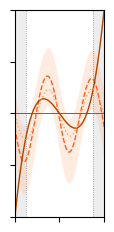

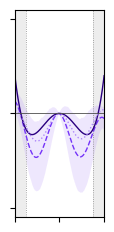

In [19]:
# =====================================================================
#  §10 --- Styled symmetric-DW force and potential panels for export.
#  Same figure pair as the other gates; the compiled curve is the one that
#  has been through the frozen inverse (see the flag below).
#
#  COMPILED_THROUGH_ESTIMATOR selects which compiled curve is drawn:
#    True   the compiled circuit after the frozen n_max inverse (F_COMP_EST,
#           from section 4.1).  Like-for-like against the data, since both have been
#           through the same band limit.  This is the default.
#    False  the exact compiled pointwise force (FPOINT_COMP) and, for the
#           potential, the compiled phase profile VPHASE_COMP.  The ceiling
#           the inverse is trying to reach, not a fair comparison to the data.
#
#  Note the two branches do not plot the same KIND of object in the potential
#  figure: True integrates the band-limited force, False shows -arg(K_g).
#  They differ by the band limit, which is the point of the switch.
#
# =====================================================================
from matplotlib.ticker import MultipleLocator

SAVE_FOR_EXPORT = True   # True: no title/axis labels/tick numbers, small figsize
                         # False: title + axis labels, bigger preview figsize

CM = 1 / 2.54
FIGSIZE_EXPORT  = (3 * CM, 6 * CM)
FIGSIZE_PREVIEW = (8.4, 5.2)
FIGSIZE = FIGSIZE_EXPORT if SAVE_FOR_EXPORT else FIGSIZE_PREVIEW

LW = 1.0
MARKER_EVERY = None
MARKER       = "o"
MARKER_SIZE  = 2.5

# --- force plot: all orange, three shades -------------------------------
FORCE_COLOR_TARGET   = "#AE4500"   # dark orange  — programmed target
FORCE_COLOR_RECON    = "#FB6023"   # mid orange   — deconvolved experiment
FORCE_COLOR_COMPILED = "#FFA366"   # light orange — compiled accepted branch

# --- potential plot: all purple, matching shades/linestyles -------------
POT_COLOR_TARGET   = "#2A0080"
POT_COLOR_RECON    = "#7534F8"
POT_COLOR_COMPILED = "#AE88F9"

LS_RECON, LS_TARGET, LS_COMPILED = "--", "-", ":"
COLOR_BOUNDARY = "0.55"

# --- axis limits / ticks, per plot --------------------------------------
XLIM = (-2.0, 2.0)
YLIM_FORCE     = (-2.0, 2.0)
YLIM_POTENTIAL = (-1.1, 1.1)
XTICK_STEP_FORCE     = 2.0
YTICK_STEP_FORCE     = 1.0
XTICK_STEP_POTENTIAL = 2.0
YTICK_STEP_POTENTIAL = 1.0

# Which compiled curve to draw; see the header.  True is the like-for-like
# comparison against the data and is what the paper figures use.
COMPILED_THROUGH_ESTIMATOR = True

DESIGN_HALF_WIDTH = 2.0
BOUNDARY_INNER = TOPOLOGY_WINDOW[-1]

plt.rcParams.update({
    "font.size": 8,
    "font.family": "sans-serif",
    "font.sans-serif": ["Calibri"],
    "figure.facecolor": "none",
    "axes.facecolor": "none",
    "savefig.transparent": True,
    "svg.fonttype": "none",
})

marker_kwargs = dict(marker=MARKER, markevery=MARKER_EVERY, markersize=MARKER_SIZE) \
                if MARKER_EVERY else {}


def add_design_range_shading(ax):
    for sign in (+1, -1):
        lo, hi = sorted((sign * BOUNDARY_INNER, sign * DESIGN_HALF_WIDTH))
        ax.axvspan(lo, hi, color=COLOR_BOUNDARY, alpha=0.15, lw=0, zorder=0)
        ax.axvline(sign * BOUNDARY_INNER, color=COLOR_BOUNDARY,
                   linestyle=":", linewidth=0.6, zorder=1)


def style_axes(ax, title, xlabel, ylabel):
    if not SAVE_FOR_EXPORT:
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    else:
        ax.tick_params(labelbottom=False, labelleft=False)


def apply_axis_limits(ax, ylim=None, xtick=None, ytick=None):
    ax.set_xlim(XLIM)
    if ylim is not None and ylim != (None, None):
        ax.set_ylim(ylim)
    if xtick is not None:
        ax.xaxis.set_major_locator(MultipleLocator(xtick))
    if ytick is not None:
        ax.yaxis.set_major_locator(MultipleLocator(ytick))


# ============================================================
#  Data prep.  Potentials are referenced to the reconstructed barrier.
# ============================================================
xs = XGRID[measured_support]
vref = float(roots[1]) if len(roots) == 3 else 0.0   # the reconstructed barrier

Vrec = integrate_force(xs, rec["force"][measured_support], zero_at=vref)
vb = np.array([integrate_force(xs, f[measured_support], vref)
               for f in boot_force if np.all(np.isfinite(f[measured_support]))])
vlo, vhi = np.nanpercentile(vb, [2.5, 97.5], axis=0)
print(f"bootstrap draws usable for the potential: {len(vb)} of {len(boot_force)}")

Vtar_s = V_target(xs) - V_target(vref)

if COMPILED_THROUGH_ESTIMATOR:
    # F_COMP_EST is built on XGRID (section 4.1), so it is not resampled.
    assert np.shape(F_COMP_EST) == np.shape(XGRID), "F_COMP_EST must be on XGRID"
    Fcomp = np.asarray(F_COMP_EST, float)
    Vcomp = integrate_masked(Fcomp, measured_support, zero_at=vref)[measured_support]
    _comp_label = fr"compiled through $|n|\leq{NMAX}$ inverse"
else:
    Fcomp = np.interp(XGRID, XCOMP, FPOINT_COMP)
    Vcomp = np.interp(xs, XCOMP, VPHASE_COMP)
    Vcomp = Vcomp - np.interp(vref, xs, Vcomp)
    _comp_label = "compiled accepted branch"

print(f"compiled curve plotted: {_comp_label}"
      f"   (COMPILED_THROUGH_ESTIMATOR = {COMPILED_THROUGH_ESTIMATOR})")


# ============================================================
#  Figure 1: pointwise force  (all orange)
# ============================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(XGRID, flo, fhi, color=FORCE_COLOR_COMPILED, alpha=0.2, lw=0,
                label="95% raw-shot + calibration band")
ax.plot(XGRID, rec["force"], LS_RECON, color=FORCE_COLOR_RECON, lw=LW,
        label=fr"deconvolved, $|n|\leq{NMAX}$", **marker_kwargs)
ax.plot(XGRID, dV_target(XGRID), LS_TARGET, color=FORCE_COLOR_TARGET, lw=LW,
        label=r"programmed $V'(X)=-0.6X+0.4X^3$")
ax.plot(XGRID, Fcomp, LS_COMPILED, color=FORCE_COLOR_COMPILED, lw=LW, label=_comp_label)
ax.axhline(0, lw=0.6, color="0.3")
add_design_range_shading(ax)
apply_axis_limits(ax, ylim=YLIM_FORCE, xtick=XTICK_STEP_FORCE, ytick=YTICK_STEP_FORCE)
style_axes(ax, "Symmetric DW: deconvolved pointwise force", r"$X$", r"$V'_{\rm exp}(X)$")
if not SAVE_FOR_EXPORT:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "12_force_vs_target.svg", format="svg", transparent=True)
plt.show()


# ============================================================
#  Figure 2: potential  (all purple, matching linestyles)
# ============================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(xs, vlo, vhi, color=POT_COLOR_COMPILED, alpha=0.2, lw=0,
                label="95% raw-shot + calibration band")
ax.plot(xs, Vrec, LS_RECON, color=POT_COLOR_RECON, lw=LW,
        label="reconstructed potential", **marker_kwargs)
ax.plot(xs, Vtar_s, LS_TARGET, color=POT_COLOR_TARGET, lw=LW,
        label=r"programmed $-0.3X^2+0.1X^4$")
ax.plot(xs, Vcomp, LS_COMPILED, color=POT_COLOR_COMPILED, lw=LW, label=_comp_label)
ax.axhline(0, lw=0.6, color="0.3")
add_design_range_shading(ax)
apply_axis_limits(ax, ylim=YLIM_POTENTIAL, xtick=XTICK_STEP_POTENTIAL, ytick=YTICK_STEP_POTENTIAL)
style_axes(ax, "Symmetric DW: reconstructed potential", r"$X$", r"$V(X)-V(X_{\rm ref})$")
if not SAVE_FOR_EXPORT:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "13_potential_vs_target.svg", format="svg", transparent=True)
plt.show()


# ============================================================
#  CSV export
# ============================================================
pd.DataFrame({
    "X": XGRID, "a": rec["a"], "q": rec["q"],
    "F_point": rec["force"], "F_lo95": flo, "F_hi95": fhi,
    "F_programmed": dV_target(XGRID),
    "F_compiled_plotted": Fcomp,
    "F_compiled_through_estimator": np.asarray(F_COMP_EST, float),
    "F_compiled_exact": np.interp(XGRID, XCOMP, FPOINT_COMP),
    "A_compiled": np.interp(XGRID, XCOMP, AMPL_COMP),
}).to_csv(OUT / "23_reconstruction_curves.csv", index=False)